In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


## Adding W&B API key

In [2]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
WB_KEY = user_secrets.get_secret("WANDB_API_KEY")


In [3]:
import wandb

wandb.login(key=WB_KEY)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [4]:
!pip install -q chonkie sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.8/233.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.2/387.2 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 50.9 MB/s eta 0:00:00


In [5]:
import wandb

print("Initializing wandb")

run = wandb.init(
    entity="ambatwar-iitm",
    project="dlgenai-t226",
    name="mcq-solver-full-pipeline",
    config={
        "task": "smart-mcq-solver-challenge",
    },
)

print("W&B run:", run.url)

Initializing wandb


wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260715_182455-e7kvkpgn
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run mcq-solver-full-pipeline
wandb: ⭐️ View project at https://wandb.ai/ambatwar-iitm/dlgenai-t226
wandb: 🚀 View run at https://wandb.ai/ambatwar-iitm/dlgenai-t226/runs/e7kvkpgn


W&B run: https://wandb.ai/ambatwar-iitm/dlgenai-t226/runs/e7kvkpgn


## Step 1 - Setup & environment check

In [6]:
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import transformers

import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.system(), platform.release())
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("PyTorch     :", torch.__version__)
print("Transformers:", transformers.__version__)
print("-" * 45)

# The device we'll use for all tensor computation.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device      :", device)
if device == "cuda":
    print("GPU         :", torch.cuda.get_device_name(0))
    print("VRAM (GB)   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("-" * 45)

# Confirm the dataset files exist (paths are relative to this notebook's folder).
DATA_DIR = Path("/kaggle/input/competitions/smart-mcq-solver-challenge")
for fname in ["train.csv", "test.csv", "sample_submission.csv"]:
    fpath = DATA_DIR / fname
    status = "FOUND   " if fpath.exists() else "MISSING!"
    print(f"{fname:22s} {status} -> {fpath}")

#import os
#from kaggle_secrets import UserSecretsClient
#os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

Python      : 3.12.13
Platform    : Linux 6.12.90+
NumPy       : 2.4.6
Pandas      : 2.3.3
PyTorch     : 2.10.0+cpu
Transformers: 5.0.0
---------------------------------------------
Device      : cpu
---------------------------------------------
train.csv              FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
test.csv               FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/test.csv
sample_submission.csv  FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv


## Step 2 - Reading input

In [7]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
sample_sub = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")

train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [8]:
test.head()

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [9]:
train.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


In [10]:
# check the shape of train and test
print(train.shape)
print(test.shape)
print(sample_sub.shape)

(2000, 8)
(500, 7)
(500, 2)


In [11]:
print("train columns:", list(train.columns))
print("test columns :", list(test.columns))
print()

print("Missing values per column (train):")
print(train.isna().sum().to_string())
print()

train columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
test columns : ['id', 'prompt', 'A', 'B', 'C', 'D', 'E']

Missing values per column (train):
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0



In [12]:
def show_question(row, show_answer=True):
    """ Preety-print a single question row so it is easy to read. """
    print("PROMPT:")
    print("  " + str(row["prompt"]))
    print()
    for opt in ["A", "B", "C", "D", "E"]:
        print(f"  {opt}) {row[opt]}")
    if show_answer and "answer" in row.index:
        print()
        print(" CORRECT ANSWER:", row["answer"])

print("=" * 80)
print("ONE EXAMPLE FROM THE TRAINING SET")
print("=" * 80)
show_question(train.iloc[0])
print("=" *80)

ONE EXAMPLE FROM THE TRAINING SET
PROMPT:
  Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.

  A) Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.
  B) Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.
  C) Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is insignificant, and human existence is solely based on the present.
  D) Ma

## Step 3 - Explore the data (EDA)

EDA stands for Exploratory Data Analysis. Before any modeling we ask simple questions about the data, because the answers change every later decision:

1. **How are the correct answers distributed across A, B, C, D, E?**
   - If they are roughly equal, there is no shortcut: a constant guess like "A B C" cannot beat chance.
   - If one letter is much more common, even a simple baseline can exploit that bias.
2. **How long are the prompts and options (in words)?**
   - This sets the maximum sequence length we feed a transformer later, which directly drives GPU memory use.

Run the cell below.

In [13]:
train["answer"]

0       B
1       A
2       C
3       B
4       A
       ..
1995    B
1996    E
1997    D
1998    B
1999    C
Name: answer, Length: 2000, dtype: object

Correct answer distribution in train (out of 2000):
 A:  369 (18.4%)
 B:  490 (24.5%)
 C:  459 (23.0%)
 D:  358 (17.9%)
 E:  324 (16.2%)

Prompt length in words:
count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0

Longest option length in words (per question):
count    2000.0
mean       30.5
std        19.0
min         1.0
25%        17.0
50%        28.0
75%        42.0
max       118.0


Text(0.5, 0, 'words per prompt')

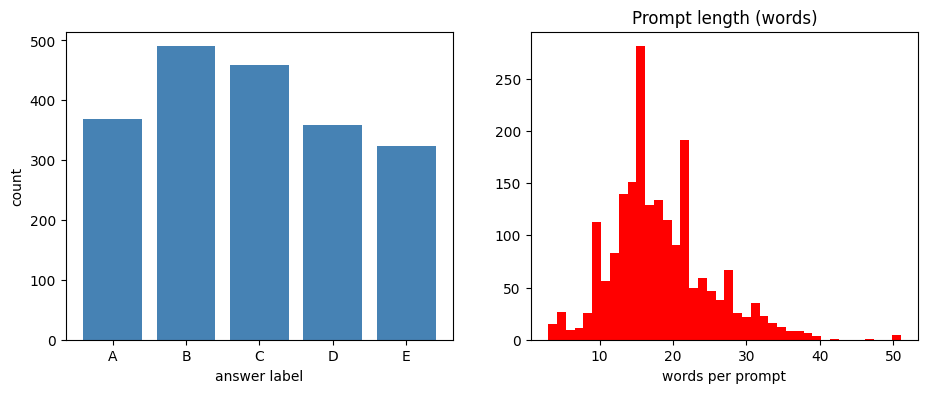

In [14]:
# === Step 3: Explore the data (EDA) ===
import matplotlib.pyplot as plt

option_cols = ["A", "B", "C", "D", "E"]

# --- 1) Distribution of the correct answer label ---
answer_counts = train["answer"].value_counts().reindex(option_cols).fillna(0).astype(int)
answer_percent = (train["answer"].value_counts(normalize=True).reindex(option_cols).fillna(0) * 100).round(1)
print("Correct answer distribution in train (out of 2000):")
for label in option_cols:
    print(f" {label}: {answer_counts[label]:4d} ({answer_percent[label]}%)")
print()

# --- 2) Text length analysis (counted in words) ---
train["prompt_words"] = train["prompt"].str.split().str.len()
train["max_option_words"] = train[option_cols].apply(
    lambda r: max(len(str(x).split()) for x in r), axis=1
)

print("Prompt length in words:")
print(train["prompt_words"].describe().round(1).to_string())
print()
print("Longest option length in words (per question):")
print(train["max_option_words"].describe().round(1).to_string())

# --- 3) Visualize ---
figure, axes = plt.subplots(1, 2, figsize = (11, 4))
axes[0].bar(answer_counts.index, answer_counts.values, color="steelblue")
axes[0].set_xlabel("answer label")
axes[0].set_ylabel("count")

axes[1].hist(train["prompt_words"], bins=40, color="red")
axes[1].set_title("Prompt length (words)")
axes[1].set_xlabel("words per prompt")


It's mildly imbalanced. B and C come up more often; E least. The data isn't perfectly flat, so the smartest constant guess is the three most frequent letters in order: "B C A", not "A B C". That's a small but free edge we'll measure in a moment. The key lesson: a model still has to actually read the question - you can't win on label bias alone here.

Prompt length (right chart): most prompts are 10-30 words (peak ~15), tailing off by ~50. Prompts are short.

## Step 4 - Build a local scoreboard (metric + validation split + baselines)

We cannot see the test answers, so we need our own honest way to measure progress. Three pieces:

1. **The MAP@3 metric, written by hand.** With one correct answer per question it is simply `1 / (rank of the correct label)` if that label lands in our top 3, otherwise 0. We verify it against the exact example from the problem statement.
2. **A validation set.** We hold out 20% of the training data (stratified, so the A-E balance is preserved). We build and tune on the other 80%, then score ourselves on this untouched 20%. This is how we estimate our leaderboard score before ever submitting.
3. **Two constant baselines** - always guess "A B C", and always guess the three most frequent answers. A baseline is the bar every fancier model must clear to be worth its complexity.

Important idea - **data leakage**: we compute the "most frequent" order from the *training split only*, never from validation. Using the validation data to make our predictions would flatter the score dishonestly.

Run the cell below.

In [15]:
# === Step 4: Local scoreboard - MAP@3 metric, validation split, constant baselines ===
from sklearn.model_selection import train_test_split


# 1) Write the MAP@3 metric ourselves (exactly one correct label per question).
def average_precision_at_3(true_label, predicted_labels):
    """Score one question: 1.0 if correct is 1st, 0.5 if 2nd, 1/3 if 3rd, else 0.0."""
    for rank, label in enumerate(predicted_labels[:3], start=1):
        if label == true_label:
            return 1.0 / rank
    return 0.0


def map_at_3(true_labels, predicted_lists):
    """Mean of the per-question scores over the whole set."""
    scores = [average_precision_at_3(t, p) for t, p in zip(true_labels, predicted_lists)]
    return sum(scores) / len(scores)


# Sanity check against the example in the problem statement (correct answer = A):
assert average_precision_at_3("A", ["A", "B", "C"]) == 1.0
assert average_precision_at_3("A", ["B", "A", "C"]) == 0.5
assert abs(average_precision_at_3("A", ["C", "D", "A"]) - 1 / 3) < 1e-9
assert average_precision_at_3("A", ["C", "D", "E"]) == 0.0
print("MAP@3 metric passes the sanity checks.\n")

# 2) Hold out 20% of train as a validation set (stratified to preserve answer balance).
train_split, valid_split = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["answer"]
)
valid_true = valid_split["answer"].tolist()
print(f"train_split: {len(train_split)} rows   valid_split: {len(valid_split)} rows\n")

# 3) Constant baselines. The 'frequency' order is learned ONLY from train_split (no leakage).
freq_order = train_split["answer"].value_counts().index.tolist()[:3]
print("Three most frequent answers in train_split:", freq_order, "\n")

baselines = {
    "constant 'A B C'": ["A", "B", "C"],
    f"constant '{' '.join(freq_order)}' (most frequent)": freq_order,
}

scoreboard = {}
for name, guess in baselines.items():
    preds = [guess] * len(valid_split)          # same guess for every validation question
    scoreboard[name] = map_at_3(valid_true, preds)

print("Local validation MAP@3 (higher is better):")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log(scoreboard)

MAP@3 metric passes the sanity checks.

train_split: 1600 rows   valid_split: 400 rows

Three most frequent answers in train_split: ['B', 'C', 'A'] 

Local validation MAP@3 (higher is better):
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'


Conclusion: Getting around 0.42 with no understanding of the question means the answer distribution is somewhat imbalanced.

## Step 5 - First real models: TF-IDF + Logistic Regression, TF-IDF + SVM

This is our first method that actually looks at the question text. Each
(prompt, option) pair is turned into one TF-IDF row, labeled 1 if that option
is the correct answer and 0 otherwise, then we train two classic ML
classifiers on those rows: **Logistic Regression** and a **linear SVM**. At
prediction time each of the 5 options for a question gets a score from the
classifier, we rank them, and keep the top 3.


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

option_cols = ["A", "B", "C", "D", "E"]

# 1) Fit the vectorizer on the TRAIN SPLIT text only (prompts + options) -> no leakage.
corpus = train_split["prompt"].astype(str).tolist()
for c in option_cols:
    corpus += train_split[c].astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
vectorizer.fit(corpus)
print("Vocabulary size:", len(vectorizer.vocabulary_))


def build_pairwise_rows(df):
    """Turn each question into 5 (prompt+option) rows, one per option,
    labeled 1 if that option is the correct answer, else 0."""
    df = df.reset_index(drop=True)
    texts, labels, qids = [], [], []
    for i, row in df.iterrows():
        for c in option_cols:
            texts.append(str(row["prompt"]) + " [SEP] " + str(row[c]))
            labels.append(1 if row.get("answer") == c else 0)
            qids.append(i)
    return texts, labels, qids

from collections import defaultdict

def scores_to_top3(scores, qids):
    """Group per-option scores back into per-question rankings of top-3 letters."""
    by_q = defaultdict(list)
    for idx, (score, qid) in enumerate(zip(scores, qids)):
        c = option_cols[idx % len(option_cols)]
        by_q[qid].append((c, score))
    preds = []
    for qid in sorted(by_q):
        ranked = sorted(by_q[qid], key=lambda x: x[1], reverse=True)
        preds.append([c for c, _ in ranked[:3]])
    return preds

# 2) Build pairwise train/valid rows and vectorize.
train_texts, train_labels, _ = build_pairwise_rows(train_split)
X_train, y_train = vectorizer.transform(train_texts), train_labels

valid_texts, _, valid_qids = build_pairwise_rows(valid_split)
X_valid = vectorizer.transform(valid_texts)

# 3) TF-IDF + Logistic Regression
logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train, y_train)
logreg_scores = logreg.predict_proba(X_valid)[:, 1]
valid_preds_logreg = scores_to_top3(logreg_scores, valid_qids)
scoreboard["TF-IDF + Logistic Regression"] = map_at_3(valid_true, valid_preds_logreg)
print(f"TF-IDF + Logistic Regression MAP@3: {scoreboard['TF-IDF + Logistic Regression']:.4f}")
wandb.log({"TF-IDF + Logistic Regression": scoreboard["TF-IDF + Logistic Regression"]})

# 4) TF-IDF + SVM (LinearSVC - fast and effective on sparse TF-IDF features)
svm = LinearSVC(class_weight="balanced")
svm.fit(X_train, y_train)
svm_scores = svm.decision_function(X_valid)
valid_preds_svm = scores_to_top3(svm_scores, valid_qids)
scoreboard["TF-IDF + SVM"] = map_at_3(valid_true, valid_preds_svm)
print(f"TF-IDF + SVM MAP@3: {scoreboard['TF-IDF + SVM']:.4f}")
wandb.log({"TF-IDF + SVM": scoreboard["TF-IDF + SVM"]})

print("\nScoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")


Vocabulary size: 10275
TF-IDF + Logistic Regression MAP@3: 0.9683
TF-IDF + SVM MAP@3: 0.9721

Scoreboard so far:
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'


## Step 5.5 - (Optional) Early checkpoint submission

You don't have to wait until BERT is done to submit. This cell takes whichever
TF-IDF model scored higher above, **retrains it on the full labeled `train.csv`**
(all 2,000 questions - no need to hold out validation rows for the real
submission), predicts on `test.csv`, and writes `submission.csv` in the exact
format the competition expects. Run Steps 1-5 + this cell, then submit that
file, to sanity-check your whole pipeline before spending time on the bigger
models.

In [17]:
# === Step 5.5: Early checkpoint submission (TF-IDF baseline) ===
# Pick whichever of the two TF-IDF models did better on the validation split.
best_tfidf_name = max(
    ["TF-IDF + Logistic Regression", "TF-IDF + SVM"],
    key=lambda name: scoreboard[name],
)
print(f"Using '{best_tfidf_name}' for the early submission "
      f"(val MAP@3 = {scoreboard[best_tfidf_name]:.4f})")

# Refit the vectorizer + chosen classifier on ALL labeled data (train, not train_split) -
# more training data almost always helps, and we no longer need a holdout for this.
full_corpus = train["prompt"].astype(str).tolist()
for c in option_cols:
    full_corpus += train[c].astype(str).tolist()

final_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
final_vectorizer.fit(full_corpus)

full_texts, full_labels, _ = build_pairwise_rows(train)
X_full = final_vectorizer.transform(full_texts)

if best_tfidf_name == "TF-IDF + Logistic Regression":
    final_clf = LogisticRegression(max_iter=1000, class_weight="balanced")
    final_clf.fit(X_full, full_labels)
    score_fn = lambda X: final_clf.predict_proba(X)[:, 1]
else:
    final_clf = LinearSVC(class_weight="balanced")
    final_clf.fit(X_full, full_labels)
    score_fn = lambda X: final_clf.decision_function(X)

# Predict on the test set (no "answer" column, so labels are all 0 - ignored).
test_texts, _, test_qids = build_pairwise_rows(test.assign(answer=None))
X_test = final_vectorizer.transform(test_texts)
test_scores = score_fn(X_test)
test_top3 = scores_to_top3(test_scores, test_qids)

submission = pd.DataFrame({
    "ID": test["id"].values,
    "Prediction": [" ".join(row) for row in test_top3],
})
submission.to_csv("submission.csv", index=False)

print("Wrote submission.csv  | shape:", submission.shape)
print(submission.head(10).to_string(index=False))
print("\nNext: Save Version -> Submit to Competition in the Kaggle UI,")
print("or:  kaggle competitions submit -c smart-mcq-solver-challenge \\")
print("       -f submission.csv -m \"TF-IDF baseline\"")


Using 'TF-IDF + SVM' for the early submission (val MAP@3 = 0.9721)
Wrote submission.csv  | shape: (500, 2)
 ID Prediction
  1      A E C
  2      B E A
  3      B E D
  4      E C D
  5      C A D
  6      D E C
  7      E D A
  8      B E A
  9      C D A
 10      B D C

Next: Save Version -> Submit to Competition in the Kaggle UI,
or:  kaggle competitions submit -c smart-mcq-solver-challenge \
       -f submission.csv -m "TF-IDF baseline"
